In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, roc_auc_score

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src import scorecard as sc

train = pd.read_parquet(ROOT / "data" / "processed" / "train.parquet")

SEG = ["AGE_YEARS", "AMT_INCOME_TOTAL", "CREDIT_TO_INCOME",
       "ANNUITY_TO_INCOME", "YEARS_EMPLOYED", "BUREAU_ACTIVE_COUNT"]

seg = train[SEG].copy()
seg["AMT_INCOME_TOTAL"] = np.log1p(seg["AMT_INCOME_TOTAL"])            # tame the huge incomes
seg["YEARS_EMPLOYED"] = seg["YEARS_EMPLOYED"].fillna(0)                # pensioners / unemployed
seg["BUREAU_ACTIVE_COUNT"] = seg["BUREAU_ACTIVE_COUNT"].fillna(0)      # no bureau record = 0 loans
seg = seg.clip(seg.quantile(0.01), seg.quantile(0.99), axis=1)          # cap extreme values
seg = seg.fillna(seg.median())                                         # any remaining gaps

Z = StandardScaler().fit_transform(seg)
print(Z.shape)
print(pd.DataFrame(Z, columns=SEG).describe().loc[["mean", "std"]].round(2))


(CVXPY) Nov 10 11:31:24 AM: Encountered unexpected exception importing solver HIGHS:
ImportError('/home/fiza/Credit_Risk/.venv/lib/python3.12/site-packages/highspy/_core.cpython-312-x86_64-linux-gnu.so: undefined symbol: _ZN5Highs13releaseMemoryEv')


(215257, 6)
      AGE_YEARS  AMT_INCOME_TOTAL  CREDIT_TO_INCOME  ANNUITY_TO_INCOME  \
mean       -0.0              -0.0               0.0                0.0   
std         1.0               1.0               1.0                1.0   

      YEARS_EMPLOYED  BUREAU_ACTIVE_COUNT  
mean             0.0                  0.0  
std              1.0                  1.0  


K=2: inertia=1,005,391  silhouette=0.227
K=3: inertia=876,702  silhouette=0.184
K=4: inertia=766,077  silhouette=0.196
K=5: inertia=674,675  silhouette=0.198
K=6: inertia=617,773  silhouette=0.185
K=7: inertia=577,141  silhouette=0.179
K=8: inertia=549,200  silhouette=0.171


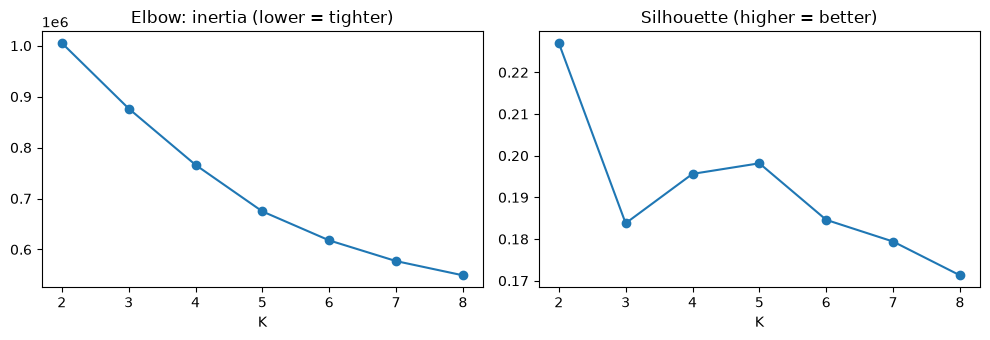

In [2]:
results = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z)
    sil = silhouette_score(Z, km.labels_, sample_size=10000, random_state=42)
    results.append((k, km.inertia_, sil))
    print(f"K={k}: inertia={km.inertia_:,.0f}  silhouette={sil:.3f}")

res = pd.DataFrame(results, columns=["k", "inertia", "silhouette"])
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(res["k"], res["inertia"], marker="o"); ax[0].set_title("Elbow: inertia (lower = tighter)")
ax[1].plot(res["k"], res["silhouette"], marker="o"); ax[1].set_title("Silhouette (higher = better)")
for a in ax: a.set_xlabel("K")
plt.tight_layout(); plt.show()
